# 07 - Specificity: AD vs other dementias (GSE120584)

Notebook 04 showed the AD-vs-NC model calls **88% of DLB and 89% of VaD patients "AD"**, the same rate as
real AD. So the serum miRNA signal may mark *dementia in general*. This notebook asks directly:

1. Do serum miRNAs differ between AD and dementia with Lewy bodies (DLB) or vascular dementia (VaD)?
2. Can a model separate AD from other dementias, and do ncRNAs add anything beyond age, sex, APOE4?
3. How much of the AD-vs-NC signature is shared with DLB and VaD?

| Task | Positive | Negative |
|---|---|---|
| AD_vs_DLB | AD | DLB |
| AD_vs_VaD | AD | VaD |
| AD_vs_other | AD | DLB + VaD (primary endpoint) |
| Dem_vs_NC | AD + DLB + VaD | NC (reference: a "dementia detector") |

Same safeguards as before: development on the training split only (nested CV), configuration locked in
`results/models/07_locked_config.json` **before** the held-out test split is scored once.
DLB and VaD test samples were scored in notebook 04 only by the AD-vs-NC model; no model in this notebook
has seen them. Runs: `src/run_specificity.py`.

In [1]:
import sys, json, warnings
sys.path.append("../src")
warnings.filterwarnings("ignore")
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.metrics import roc_auc_score, roc_curve
from statsmodels.stats.multitest import multipletests

from utils import ROOT, FIGURES
from modeling import evaluate_with_threshold, metrics, bootstrap_auc_ci, bootstrap_auc_diff
from biomarkers import consensus
from run_specificity import TASKS, SETS, ALGOS, features, task_data

RUNS = ROOT / "results" / "models" / "07_runs"
TAB = ROOT / "results" / "tables"
FIG = FIGURES / "07_specificity"; FIG.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid")
def savefig(n): plt.savefig(FIG / f"{n}.png", dpi=150, bbox_inches="tight")
ORDER = ["NC", "MCI", "AD", "DLB", "VaD"]

F, clin, ncrna = features("train")
clin["diagnosis"].value_counts().reindex(ORDER)

diagnosis
NC     230
MCI     26
AD     816
DLB    135
VaD     73
Name: count, dtype: int64

## 1. Who are the groups? (training split)

In [2]:
g = clin.assign(female=(clin.sex == "female").astype(int)).groupby("diagnosis")
demo = pd.DataFrame({"n": g.size(), "age": g.age.mean(), "female": g.female.mean(),
                     "APOE4_carrier": g.apoe4.mean(), "detect_rate": g.detect_rate.mean()}).reindex(ORDER)
rows = []
for other in ["DLB", "VaD"]:
    a, b = clin[clin.diagnosis == "AD"], clin[clin.diagnosis == other]
    rows.append({"comparison": f"AD vs {other}",
                 "age_p": stats.mannwhitneyu(a.age, b.age).pvalue,
                 "female_p": stats.chi2_contingency(pd.crosstab(pd.concat([a, b]).diagnosis, pd.concat([a, b]).sex))[1],
                 "APOE4_p": stats.chi2_contingency(pd.crosstab(pd.concat([a, b]).diagnosis, pd.concat([a, b]).apoe4))[1],
                 "detect_rate_p": stats.mannwhitneyu(a.detect_rate, b.detect_rate).pvalue})
display(demo.round(3)); pd.DataFrame(rows).set_index("comparison").map(lambda v: f"{v:.1e}")

,n,age,female,APOE4_carrier,detect_rate
diagnosis,,,,,
NC,230,71.935,0.474,0.204,0.457
MCI,26,76.500,0.769,0.385,0.532
AD,816,79.115,0.700,0.489,0.489
DLB,135,79.319,0.600,0.319,0.506
VaD,73,78.959,0.411,0.260,0.500


,age_p,female_p,APOE4_p,detect_rate_p
comparison,,,,
AD vs DLB,9.1e-01,2.7e-02,8.2e-03,1.4e-01
AD vs VaD,9.9e-01,8.6e-07,7.1e-03,4.3e-01


Unlike AD vs NC, the dementia groups are the **same age** (about 79), so age confounding is small here.
APOE4 (an AD risk gene) and sex still differ, so they stay in every model and adjusted test.

## 2. Single-miRNA differences (adjusted for age, sex, APOE4, sample quality)

In [3]:
def adjusted_diff(groups_pos, groups_neg):
    """Vectorised OLS for all miRNAs: miRNA ~ group + age + female + apoe4 + detect_rate. Returns beta, p, FDR."""
    m = clin.diagnosis.isin(groups_pos + groups_neg)
    c = clin[m]
    D = np.column_stack([np.ones(m.sum()), c.diagnosis.isin(groups_pos).astype(float), c.age,
                         (c.sex == "female").astype(float), c.apoe4, c.detect_rate])
    Y = F.loc[m, ncrna].values
    beta, *_ = np.linalg.lstsq(D, Y, rcond=None)
    resid = Y - D @ beta
    dof = D.shape[0] - D.shape[1]
    se = np.sqrt((resid ** 2).sum(0) / dof * np.linalg.inv(D.T @ D)[1, 1])
    t = beta[1] / se
    p = 2 * stats.t.sf(np.abs(t), dof)
    return pd.DataFrame({"beta": beta[1], "p": p, "fdr": multipletests(p, method="fdr_bh")[1]}, index=ncrna)

comps = {"AD vs NC": (["AD"], ["NC"]), "DLB vs NC": (["DLB"], ["NC"]), "VaD vs NC": (["VaD"], ["NC"]),
         "AD vs DLB": (["AD"], ["DLB"]), "AD vs VaD": (["AD"], ["VaD"]), "AD vs DLB+VaD": (["AD"], ["DLB", "VaD"])}
diff = {k: adjusted_diff(*v) for k, v in comps.items()}
uni = pd.DataFrame({k: {"FDR<0.05": int((d.fdr < .05).sum()), "up": int(((d.fdr < .05) & (d.beta > 0)).sum()),
                        "down": int(((d.fdr < .05) & (d.beta < 0)).sum()), "min_p": d.p.min()} for k, d in diff.items()}).T
pd.concat({k: d.add_prefix(k.replace(" ", "_") + "_") for k, d in diff.items()}, axis=1).droplevel(0, axis=1) \
  .to_csv(TAB / "07_univariate_adjusted.csv")
uni

,FDR<0.05,up,down,min_p
AD vs NC,263.0,216.0,47.0,4.539048e-12
DLB vs NC,215.0,199.0,16.0,1.474501e-10
VaD vs NC,338.0,315.0,23.0,1.194468e-10
AD vs DLB,6.0,0.0,6.0,8.274621e-07
AD vs VaD,82.0,1.0,81.0,1.322846e-04
AD vs DLB+VaD,91.0,10.0,81.0,4.397596e-08


In [4]:
# How much of the AD-vs-NC signature is shared with other dementias?
sig = diff["AD vs NC"].index[diff["AD vs NC"].fdr < .05]
share = []
for other in ["DLB vs NC", "VaD vs NC"]:
    d = diff[other].loc[sig]
    same = np.sign(d.beta) == np.sign(diff["AD vs NC"].loc[sig, "beta"])
    rho = stats.spearmanr(diff["AD vs NC"].beta, diff[other].beta)[0]
    share.append({"comparison": other, "AD_signature_size": len(sig), "same_direction": f"{same.mean():.0%}",
                  "also_FDR<0.05_same_dir": int((same & (d.fdr < .05)).sum()),
                  "effect_correlation_all_817 (rho)": round(rho, 2)})
share = pd.DataFrame(share).set_index("comparison"); share.to_csv(TAB / "07_signature_sharing.csv"); share

,AD_signature_size,same_direction,also_FDR<0.05_same_dir,effect_correlation_all_817 (rho)
comparison,,,,
DLB vs NC,263,98%,147,0.72
VaD vs NC,263,97%,205,0.81


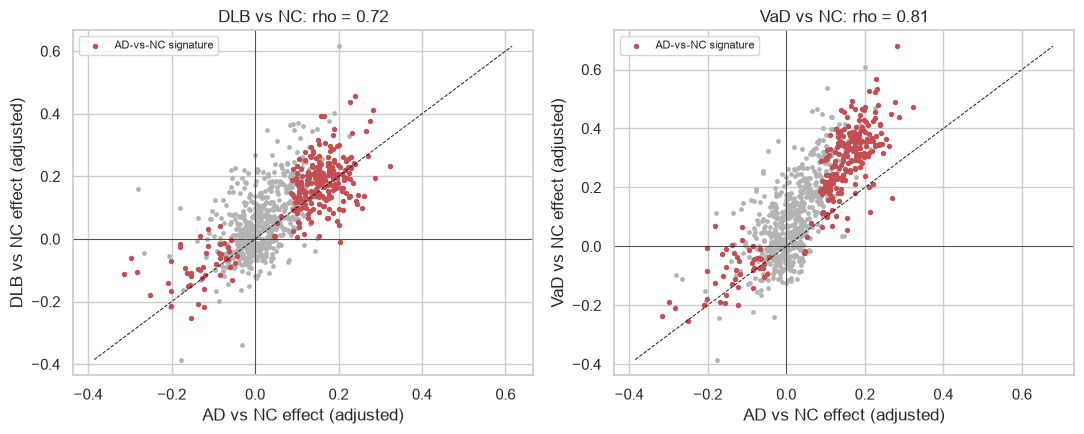

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, other in zip(axes, ["DLB vs NC", "VaD vs NC"]):
    x, yv = diff["AD vs NC"].beta, diff[other].beta
    s = diff["AD vs NC"].fdr < .05
    ax.scatter(x[~s], yv[~s], s=6, c="0.7"); ax.scatter(x[s], yv[s], s=8, c="C3", label="AD-vs-NC signature")
    lim = [min(x.min(), yv.min()), max(x.max(), yv.max())]; ax.plot(lim, lim, "k--", lw=.7)
    ax.axhline(0, c="k", lw=.5); ax.axvline(0, c="k", lw=.5)
    ax.set_xlabel("AD vs NC effect (adjusted)"); ax.set_ylabel(f"{other} effect (adjusted)")
    ax.set_title(f"{other}: rho = {stats.spearmanr(x, yv)[0]:.2f}"); ax.legend(fontsize=8)
plt.tight_layout(); savefig("shared_signature"); plt.show()

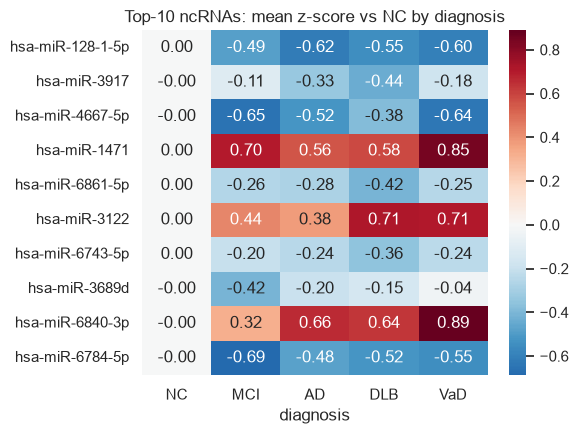

,AD vs NC,DLB vs NC,VaD vs NC,AD vs DLB+VaD
hsa-miR-128-1-5p,0.0000,0.0041,0.0026,0.9160
hsa-miR-3917,0.0001,0.0032,0.3219,0.9932
hsa-miR-4667-5p,0.0001,0.1503,0.0032,0.9818
hsa-miR-1471,0.0000,0.0072,0.0001,0.2818
hsa-miR-6861-5p,0.0000,0.0129,0.1405,0.6597
hsa-miR-3122,0.0798,0.0001,0.0011,0.0048
hsa-miR-6743-5p,0.0008,0.0001,0.0013,0.6542
hsa-miR-3689d,0.0079,0.5724,0.9792,0.2776
hsa-miR-6840-3p,0.0000,0.3072,0.0131,0.8935
hsa-miR-6784-5p,0.0000,0.0041,0.0005,0.7277


In [6]:
# The notebook-03 top-10 ncRNAs across all diagnoses (z-score relative to NC)
top10 = json.load(open(ROOT / "results" / "models" / "04_locked_config.json"))["top10"]
nc = F.loc[clin.diagnosis == "NC", top10]
z = (F[top10] - nc.mean()) / nc.std()
hm = z.groupby(clin.diagnosis).mean().reindex(ORDER).T
fig, ax = plt.subplots(figsize=(6, 4.5))
sns.heatmap(hm, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax)
ax.set_title("Top-10 ncRNAs: mean z-score vs NC by diagnosis"); plt.tight_layout(); savefig("top10_by_diagnosis"); plt.show()
top10_tab = pd.DataFrame({k: diff[k].loc[top10, "fdr"] for k in ["AD vs NC", "DLB vs NC", "VaD vs NC", "AD vs DLB+VaD"]})
top10_tab.round(4)

## 3. Models (nested CV, training split)

In [7]:
rows, oofs = [], {}
for task in TASKS:
    Ft, y = task_data(F, clin, task)
    for fs in SETS:
        for algo in ALGOS:
            r = joblib.load(RUNS / f"cv_{task}_{fs}_{algo}.joblib")
            s = r["oof"]["score"].astype(float); oofs[(task, fs, algo)] = (y, s)
            lo, hi = bootstrap_auc_ci(y, s, n=1000)
            met, _ = evaluate_with_threshold(y, r["oof"].assign(score=s), r["inner"], "balanced")
            rows.append({"task": task, "n_pos": int(y.sum()), "n_neg": int((1 - y).sum()), "feature_set": fs,
                         "algorithm": algo, "AUC": r["auc"], "AUC_95CI": f"{lo:.3f}-{hi:.3f}",
                         "balanced_acc": met["balanced_acc"], "sensitivity": met["sensitivity"],
                         "specificity": met["specificity"]})
cv = pd.DataFrame(rows); cv.to_csv(TAB / "07_cv_results.csv", index=False)
cv.round(3)

,task,n_pos,n_neg,feature_set,algorithm,AUC,AUC_95CI,balanced_acc,sensitivity,specificity
0,AD_vs_DLB,816,135,A2_clinical+quality,LogReg,0.585,0.537-0.635,0.568,0.373,0.763
1,AD_vs_DLB,816,135,A2_clinical+quality,XGBoost,0.570,0.518-0.619,0.548,0.577,0.519
2,AD_vs_DLB,816,135,C_ncrna+clinical,LogReg,0.627,0.578-0.675,0.604,0.638,0.570
3,AD_vs_DLB,816,135,C_ncrna+clinical,XGBoost,0.603,0.555-0.651,0.580,0.434,0.726
4,AD_vs_VaD,816,73,A2_clinical+quality,LogReg,0.658,0.596-0.716,0.598,0.483,0.712
5,AD_vs_VaD,816,73,A2_clinical+quality,XGBoost,0.612,0.542-0.677,0.560,0.490,0.630
6,AD_vs_VaD,816,73,C_ncrna+clinical,LogReg,0.686,0.621-0.746,0.608,0.559,0.658
7,AD_vs_VaD,816,73,C_ncrna+clinical,XGBoost,0.608,0.542-0.668,0.577,0.551,0.603
8,AD_vs_other,816,208,A2_clinical+quality,LogReg,0.618,0.576-0.660,0.585,0.381,0.788
9,AD_vs_other,816,208,A2_clinical+quality,XGBoost,0.606,0.563-0.646,0.552,0.507,0.596


In [8]:
# Added value of ncRNAs: best C model vs best A2 model, paired bootstrap on the same out-of-fold samples
gain = []
for task in TASKS:
    best = {fs: cv[(cv.task == task) & (cv.feature_set == fs)].sort_values("AUC").algorithm.iloc[-1] for fs in SETS}
    y, sa = oofs[(task, SETS[0], best[SETS[0]])]; _, sc = oofs[(task, SETS[1], best[SETS[1]])]
    d, lo, hi, p = bootstrap_auc_diff(y, sa, sc, n=2000)
    gain.append({"task": task, "clinical+quality": roc_auc_score(y, sa), "ncRNA+clinical": roc_auc_score(y, sc),
                 "gain": d, "CI_low": lo, "CI_high": hi, "p_one_sided": p})
gain = pd.DataFrame(gain).set_index("task"); gain.to_csv(TAB / "07_cv_gain.csv"); gain.round(3)

,clinical+quality,ncRNA+clinical,gain,CI_low,CI_high,p_one_sided
task,,,,,,
AD_vs_DLB,0.585,0.627,0.042,-0.015,0.100,0.074
AD_vs_VaD,0.658,0.686,0.028,-0.032,0.083,0.178
AD_vs_other,0.618,0.666,0.048,0.010,0.087,0.008
Dem_vs_NC,0.838,0.900,0.062,0.033,0.092,0.000


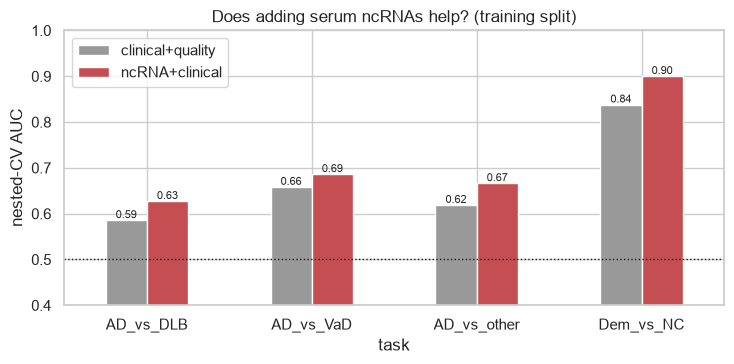

In [9]:
fig, ax = plt.subplots(figsize=(7.5, 3.8))
gp = gain[["clinical+quality", "ncRNA+clinical"]].reindex(list(TASKS))
gp.plot(kind="bar", ax=ax, color=["0.6", "C3"], rot=0)
for c in ax.containers: ax.bar_label(c, fmt="%.2f", fontsize=8)
ax.axhline(.5, c="k", ls=":", lw=1); ax.set_ylim(.4, 1); ax.set_ylabel("nested-CV AUC")
ax.set_title("Does adding serum ncRNAs help? (training split)"); plt.tight_layout(); savefig("cv_auc"); plt.show()

## 4. AD-specific candidate miRNAs (AD vs DLB + VaD)

Stability ranking as in notebook 03 (LASSO, RFE, RF, SHAP; 25 resamples; clinical covariates always in the
model). These would be the miRNAs that separate AD from *other dementias*, not from healthy people.

In [10]:
st = joblib.load(RUNS / "stability_AD_vs_other.joblib")
table, top_spec = consensus(st["freq"], st["mean_rank"])
spec = table.loc[top_spec].join(diff["AD vs DLB+VaD"].rename(columns=lambda c: f"{c}_AD_vs_other")) \
            .join(diff["AD vs NC"][["fdr"]].rename(columns={"fdr": "fdr_AD_vs_NC"}))
spec.insert(0, "rank", range(1, len(spec) + 1))
spec["in_AD_vs_NC_top10"] = spec.index.isin(top10)
spec.to_csv(TAB / "07_AD_specific_candidates.csv")
print(f"{table.qualifies.sum()} miRNAs qualify")
spec[["rank", "freq_LASSO", "freq_RFE", "freq_RF", "freq_SHAP", "n_methods_stable", "beta_AD_vs_other",
      "fdr_AD_vs_other", "fdr_AD_vs_NC", "in_AD_vs_NC_top10"]].round(3)

8 miRNAs qualify


,rank,freq_LASSO,freq_RFE,freq_RF,freq_SHAP,n_methods_stable,beta_AD_vs_other,fdr_AD_vs_other,fdr_AD_vs_NC,in_AD_vs_NC_top10
hsa-miR-6088,1,1.00,0.88,1.00,1.00,4,-0.189,0.000,0.321,False
hsa-miR-4728-5p,2,0.84,0.80,1.00,0.96,4,-0.209,0.000,0.139,False
hsa-miR-92a-2-5p,3,0.80,0.60,0.12,0.68,3,0.106,0.124,0.008,False
hsa-miR-6740-3p,4,0.92,0.96,0.00,0.00,2,0.030,0.753,0.002,False
hsa-miR-3122,5,0.12,0.16,0.96,0.60,2,-0.174,0.005,0.080,True
hsa-miR-508-5p,6,0.52,0.80,0.28,0.12,2,-0.263,0.011,0.866,False
hsa-miR-198,7,0.08,0.12,0.80,0.72,2,-0.173,0.026,0.261,False
hsa-miR-6785-5p,8,0.60,0.72,0.00,0.04,2,0.053,0.341,0.296,False


## 5. One-time held-out test

`python src/run_specificity.py --final` locked the configuration (per task and feature set: the algorithm with
the higher nested-CV AUC), refit on the full training split, chose thresholds on training predictions
(balanced accuracy), and then scored the test split once.

In [11]:
lock = json.load(open(ROOT / "results" / "models" / "07_locked_config.json"))
print("locked at", lock["locked_at"]); print(json.dumps(lock["choice"], indent=1))
fin = joblib.load(ROOT / "results" / "models" / "07_final_test.joblib")
rows = []
for (task, fs), r in fin.items():
    y, s = r["y_test"], r["test_score"]
    lo, hi = bootstrap_auc_ci(y, s, n=2000)
    met = metrics(y, s, (s >= r["threshold"]).astype(int))
    rows.append({"task": task, "feature_set": fs, "algorithm": r["algo"], "n_pos": int(y.sum()), "n_neg": int((1 - y).sum()),
                 "train_OOF_AUC": r["train_oof_auc"], "test_AUC": roc_auc_score(y, s), "AUC_95CI": f"{lo:.2f}-{hi:.2f}",
                 "balanced_acc": met["balanced_acc"], "sensitivity": met["sensitivity"], "specificity": met["specificity"]})
test = pd.DataFrame(rows); test.to_csv(TAB / "07_test_results.csv", index=False)
test.round(3)

locked at 2026-11-17T14:35:37
{
 "AD_vs_DLB": {
  "A2_clinical+quality": "LogReg",
  "C_ncrna+clinical": "LogReg"
 },
 "AD_vs_VaD": {
  "A2_clinical+quality": "LogReg",
  "C_ncrna+clinical": "LogReg"
 },
 "AD_vs_other": {
  "A2_clinical+quality": "LogReg",
  "C_ncrna+clinical": "LogReg"
 },
 "Dem_vs_NC": {
  "A2_clinical+quality": "LogReg",
  "C_ncrna+clinical": "XGBoost"
 }
}


,task,feature_set,algorithm,n_pos,n_neg,train_OOF_AUC,test_AUC,AUC_95CI,balanced_acc,sensitivity,specificity
0,AD_vs_DLB,A2_clinical+quality,LogReg,205,34,0.583,0.649,0.55-0.74,0.597,0.341,0.853
1,AD_vs_DLB,C_ncrna+clinical,LogReg,205,34,0.658,0.664,0.57-0.75,0.553,0.488,0.618
2,AD_vs_VaD,A2_clinical+quality,LogReg,205,18,0.655,0.712,0.58-0.84,0.679,0.746,0.611
3,AD_vs_VaD,C_ncrna+clinical,LogReg,205,18,0.691,0.735,0.62-0.84,0.677,0.688,0.667
4,AD_vs_other,A2_clinical+quality,LogReg,205,52,0.609,0.684,0.60-0.76,0.616,0.366,0.865
5,AD_vs_other,C_ncrna+clinical,LogReg,205,52,0.670,0.711,0.63-0.79,0.660,0.532,0.788
6,Dem_vs_NC,A2_clinical+quality,LogReg,257,58,0.832,0.895,0.84-0.94,0.828,0.864,0.793
7,Dem_vs_NC,C_ncrna+clinical,XGBoost,257,58,0.909,0.920,0.87-0.96,0.847,0.953,0.741


In [12]:
tg = []
for task in TASKS:
    a, c = fin[(task, SETS[0])], fin[(task, SETS[1])]
    d, lo, hi, p = bootstrap_auc_diff(a["y_test"], a["test_score"], c["test_score"], n=2000)
    tg.append({"task": task, "gain_ncRNA": d, "CI_low": lo, "CI_high": hi, "p_one_sided": p})
tg = pd.DataFrame(tg).set_index("task"); tg.to_csv(TAB / "07_test_gain.csv"); tg.round(3)

,gain_ncRNA,CI_low,CI_high,p_one_sided
task,,,,
AD_vs_DLB,0.015,-0.092,0.123,0.404
AD_vs_VaD,0.023,-0.076,0.123,0.348
AD_vs_other,0.027,-0.063,0.115,0.284
Dem_vs_NC,0.025,-0.008,0.060,0.068


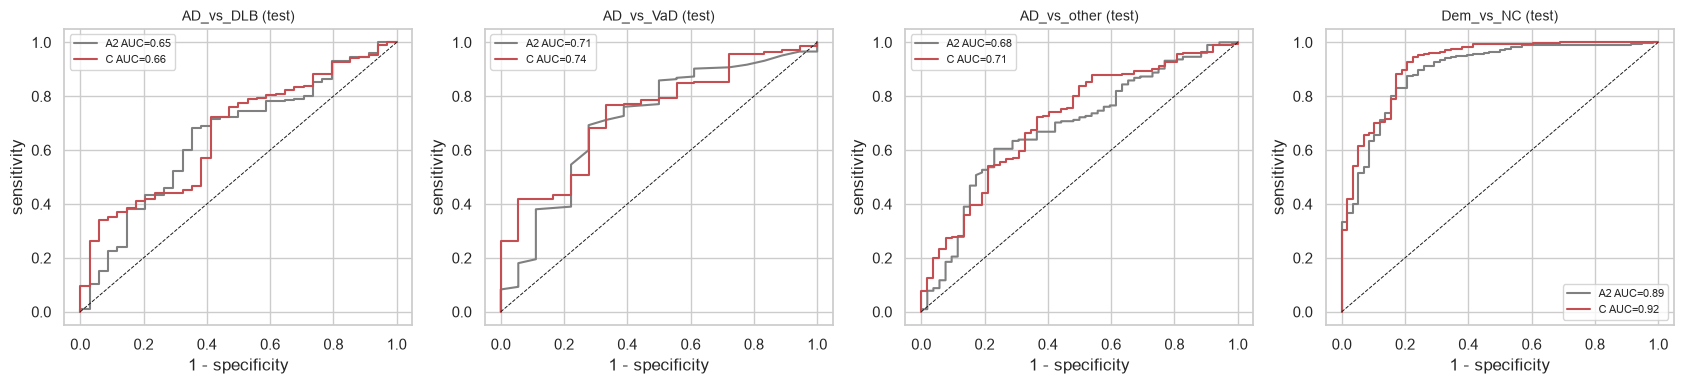

In [13]:
fig, axes = plt.subplots(1, 4, figsize=(17, 4))
for ax, task in zip(axes, TASKS):
    for fs, col in zip(SETS, ["0.5", "C3"]):
        r = fin[(task, fs)]; fpr, tpr, _ = roc_curve(r["y_test"], r["test_score"])
        ax.plot(fpr, tpr, c=col, label=f"{fs.split('_')[0]} AUC={roc_auc_score(r['y_test'], r['test_score']):.2f}")
    ax.plot([0, 1], [0, 1], "k--", lw=.7); ax.set_title(f"{task} (test)", fontsize=10); ax.legend(fontsize=8)
    ax.set_xlabel("1 - specificity"); ax.set_ylabel("sensitivity")
plt.tight_layout(); savefig("test_roc"); plt.show()

## 6. Interpretation

**1. The serum miRNA signal is mostly a general dementia signal, not AD-specific.** 97-98% of the 263
AD-vs-NC signature miRNAs change in the *same direction* in DLB and VaD (vs NC), and effects correlate
strongly across all 817 miRNAs (rho 0.72 with DLB, 0.81 with VaD). DLB vs NC and VaD vs NC have as many
significant miRNAs (215, 338) as AD vs NC (263), while AD vs DLB has only 6.

**2. Separating AD from other dementias is hard.** Nested-CV AUC with ncRNAs + clinical: AD vs DLB 0.63,
AD vs VaD 0.69, AD vs DLB+VaD 0.67 (clinical + quality alone: 0.59-0.66). ncRNAs add a small, significant
gain for AD vs other dementias in training CV (+0.048, CI +0.010 to +0.087), but on the held-out test the
gains (+0.015 to +0.027) are not significant (only 34 DLB and 18 VaD test samples; wide intervals).
Held-out test AUC: AD vs DLB 0.66, AD vs VaD 0.74, AD vs other 0.71.

**3. As a dementia detector it works well:** any dementia vs NC, test AUC 0.920 (clinical + quality: 0.895).

**4. AD-specific candidates** (AD vs DLB+VaD, stability ranking): hsa-miR-6088 and hsa-miR-4728-5p are
selected by all four methods (lower in AD than in other dementias, FDR < 0.001), followed by miR-3122,
miR-508-5p and miR-198. miR-3122 is also in the AD-vs-NC top 10. These are hypotheses, not validated markers.

**What to report:** serum miRNAs in GSE120584 detect *dementia* (AUC 0.92) far better than they identify
*which* dementia (AUC about 0.7). Claims should be framed as "dementia / neurodegeneration biomarkers with
modest AD specificity", and an AD-vs-other-dementia validation is needed before any AD-specific use.